<a href="https://colab.research.google.com/github/AsifAliSoomro103/Coffee-Machine-Simulator-Project-in-OOP-Java/blob/main/ML_Lab10_Asif_Ali_289.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LAB: HYPERPARAMETER TUNING
# Breast Cancer Classification

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [3]:

data = load_breast_cancer()
X, y = data.data, data.target

print("Dataset Shape:", X.shape)
print("Target Classes:", data.target_names)

Dataset Shape: (569, 30)
Target Classes: ['malignant' 'benign']


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 455
Testing Samples: 114


In [5]:


knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
knn_results = []

for k in k_values:
    knn_model.set_params(knn__n_neighbors=k)
    knn_model.fit(X_train, y_train)
    predictions = knn_model.predict(X_test)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, predictions)
    })

knn_results_df = pd.DataFrame(knn_results)
print(knn_results_df)

best_k = int(knn_results_df.loc[knn_results_df["Accuracy"].idxmax(), "K"])
print("Best K:", best_k)

    K  Accuracy
0   1  0.938596
1   3  0.982456
2   5  0.956140
3   7  0.973684
4   9  0.973684
5  11  0.973684
6  15  0.973684
7  21  0.964912
Best K: 3


In [6]:

best_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k))
])

best_knn.fit(X_train, y_train)
knn_predictions = best_knn.predict(X_test)

In [7]:

default_dt = DecisionTreeClassifier(random_state=42)
default_dt.fit(X_train, y_train)

default_dt_predictions = default_dt.predict(X_test)

In [8]:


param_grid = {
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_dt = grid_search.best_estimator_
dt_predictions = best_dt.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best CV Accuracy: 0.9384615384615385


In [9]:

default_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
default_rf.fit(X_train, y_train)

default_rf_predictions = default_rf.predict(X_test)

In [10]:

param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 10, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

best_rf = random_search.best_estimator_
rf_predictions = best_rf.predict(X_test)

print("Best Parameters:", random_search.best_params_)
print("Best CV Accuracy:", random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 20}
Best CV Accuracy: 0.9604395604395606


In [11]:

def evaluate_model(name, predictions):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    }

results_df = pd.DataFrame([
    evaluate_model("Default Decision Tree", default_dt_predictions),
    evaluate_model("Optimized Decision Tree", dt_predictions),
    evaluate_model("Default Random Forest", default_rf_predictions),
    evaluate_model("Optimized Random Forest", rf_predictions),
    evaluate_model("Optimized KNN", knn_predictions)
])

print(results_df.round(4))

                     Model  Accuracy  Precision  Recall  F1 Score
0    Default Decision Tree    0.9123     0.9559  0.9028    0.9286
1  Optimized Decision Tree    0.9211     0.9565  0.9167    0.9362
2    Default Random Forest    0.9561     0.9589  0.9722    0.9655
3  Optimized Random Forest    0.9561     0.9589  0.9722    0.9655
4            Optimized KNN    0.9825     0.9730  1.0000    0.9863


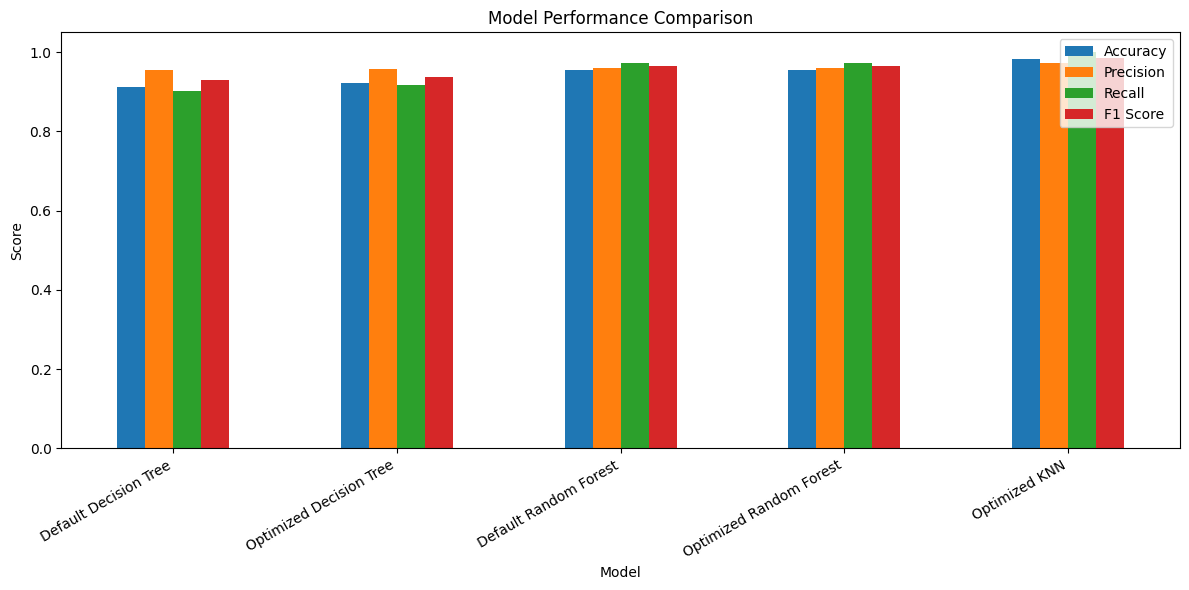

In [12]:

results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

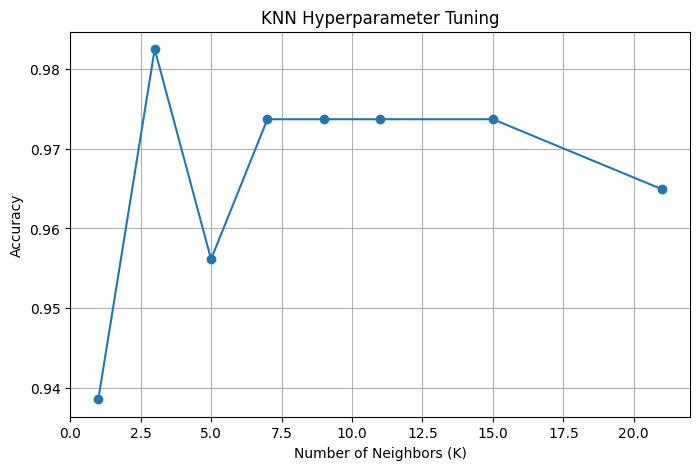

In [13]:


plt.figure(figsize=(8, 5))

plt.plot(
    knn_results_df["K"],
    knn_results_df["Accuracy"],
    marker="o"
)

plt.title("KNN Hyperparameter Tuning")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

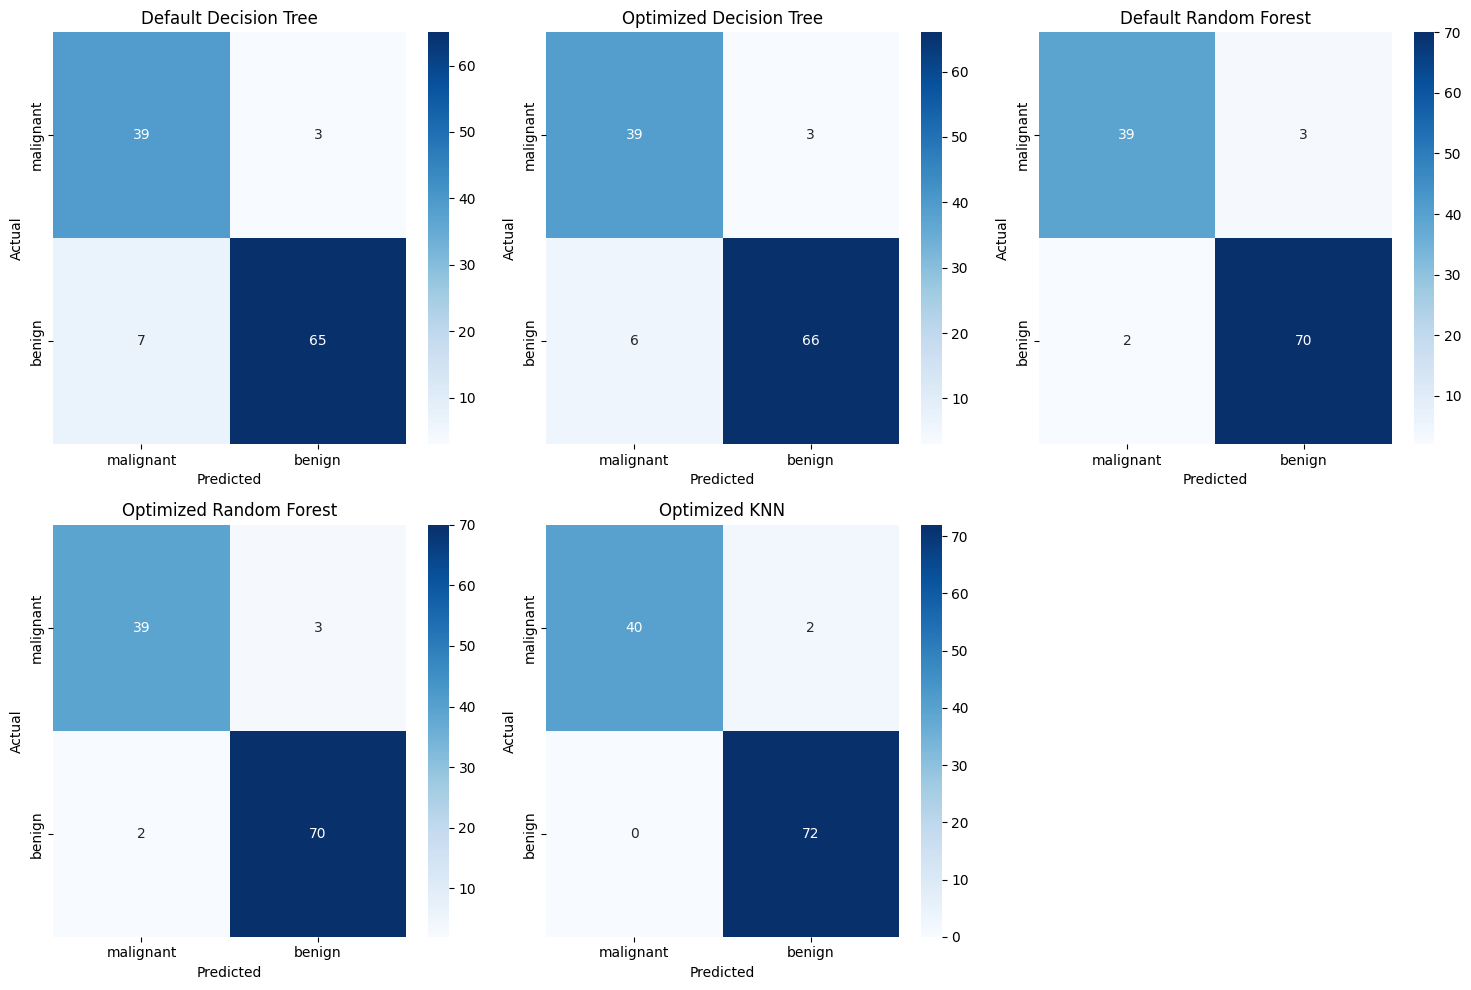

In [14]:


models = {
    "Default Decision Tree": default_dt_predictions,
    "Optimized Decision Tree": dt_predictions,
    "Default Random Forest": default_rf_predictions,
    "Optimized Random Forest": rf_predictions,
    "Optimized KNN": knn_predictions
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (name, predictions) in enumerate(models.items()):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=data.target_names,
        yticklabels=data.target_names,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

In [15]:

print("Optimized Decision Tree:")
print(classification_report(
    y_test, dt_predictions, target_names=data.target_names
))

print("Optimized Random Forest:")
print(classification_report(
    y_test, rf_predictions, target_names=data.target_names
))

print("Optimized KNN:")
print(classification_report(
    y_test, knn_predictions, target_names=data.target_names
))

Optimized Decision Tree:
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114

Optimized Random Forest:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Optimized KNN:
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted 

In [16]:

print("Default Decision Tree Accuracy:",
      accuracy_score(y_test, default_dt_predictions))

print("Optimized Decision Tree Accuracy:",
      accuracy_score(y_test, dt_predictions))

print("Default Random Forest Accuracy:",
      accuracy_score(y_test, default_rf_predictions))

print("Optimized Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Optimized KNN Accuracy:",
      accuracy_score(y_test, knn_predictions))

Default Decision Tree Accuracy: 0.9122807017543859
Optimized Decision Tree Accuracy: 0.9210526315789473
Default Random Forest Accuracy: 0.956140350877193
Optimized Random Forest Accuracy: 0.956140350877193
Optimized KNN Accuracy: 0.9824561403508771


Description of Solution

RandomizedSearchCV: Randomly selects a specified number of hyperparameter combinations from a parameter distribution and evaluates them using cross-validation.
K-Nearest Neighbors (KNN): A classification algorithm that predicts the class of a sample based on the majority class of its nearest neighbors.
Decision Tree: A tree-based classification algorithm that makes predictions using a sequence of feature-based decision rules.
Random Forest: An ensemble learning algorithm that combines multiple decision trees to improve prediction performance and reduce overfitting.
Evaluation Metrics: Accuracy, precision, recall, F1-score, and confusion matrix are used to evaluate and compare model performance.

Hyperparameter tuning helps identify suitable model configurations, but improvement in performance depends on the dataset, model, and evaluation metric.